In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost

In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset splitting
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Display settings
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")

Saving Clean_Dataset.csv to Clean_Dataset (1).csv
Dataset uploaded successfully!


In [7]:
import io

# Look for both the original file name and the auto-renamed version
file_names = ['Clean_Dataset.csv', 'Clean_Dataset (1).csv']

actual_file = None
for name in file_names:
    if name in uploaded:
        actual_file = name
        break

if not actual_file:
    raise FileNotFoundError(
        "Please upload Clean_Dataset.csv"
    )

df = pd.read_csv(io.BytesIO(uploaded[actual_file]))

print(f"Dataset loaded successfully from: {actual_file}!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully from: Clean_Dataset (1).csv!
Dataset Shape: (1470, 38)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,TotalSatisfaction,TenureRatio,CareerStartAge
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5,8,0.750000,33
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7,12,1.000000,39
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0,12,0.000000,30
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0,13,1.000000,25
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2,10,0.333333,21


In [8]:
print("========== DATASET INFORMATION ==========")

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

========== DATASET INFORMATION ==========

Shape:
(1470, 38)

Columns:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'TotalSatisfaction', 'TenureRatio', 'CareerStartAge']

Data Types:
Age                           int64
Attrition                    object
BusinessTravel               object
DailyRate                     int64
Department                   object
DistanceFromHome              int64
Education                  

In [9]:
print("========== DATA QUALITY CHECK ==========")

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nMissing Values Per Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

========== DATA QUALITY CHECK ==========

Missing Values:
0

Duplicate Records:
0

Missing Values Per Column:
Series([], dtype: int64)


In [10]:
print("Target Variable Distribution:")

print(df['Attrition'].value_counts())

print("\nTarget Variable Percentage:")

print(
    df['Attrition'].value_counts(normalize=True) * 100
)

Target Variable Distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Target Variable Percentage:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


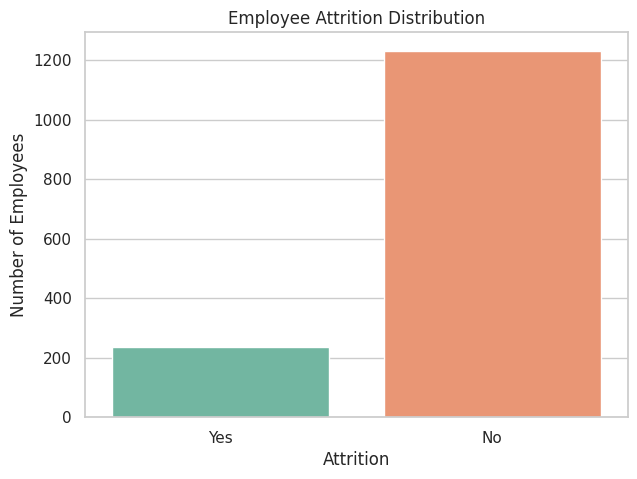

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Attrition',
    hue='Attrition',
    palette='Set2',
    legend=False
)

plt.title('Employee Attrition Distribution')
plt.xlabel('Attrition')
plt.ylabel('Number of Employees')

plt.show()

In [12]:
df['Attrition'] = (
    df['Attrition']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({'yes': 1, 'no': 0})
)

if df['Attrition'].isnull().any():
    raise ValueError("Unexpected values found in Attrition column!")

df['Attrition'] = df['Attrition'].astype(int)

print("Target variable converted successfully!")

print(df['Attrition'].value_counts())

Target variable converted successfully!
Attrition
0    1233
1     237
Name: count, dtype: int64


In [13]:
columns_to_drop = [
    'EmployeeNumber',
    'EmployeeCount',
    'Over18',
    'StandardHours'
]

existing_columns = [
    col for col in columns_to_drop if col in df.columns
]

df_model = df.drop(columns=existing_columns)

print("Removed columns:", existing_columns)
print("Final dataset shape:", df_model.shape)

df_model.head()

Removed columns: ['EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours']
Final dataset shape: (1470, 34)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,TotalSatisfaction,TenureRatio,CareerStartAge
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5,8,0.750000,33
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7,12,1.000000,39
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0,12,0.000000,30
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0,13,1.000000,25
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2,10,0.333333,21


In [14]:
X = df_model.drop('Attrition', axis=1)
y = df_model['Attrition']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Input Features Shape: (1470, 33)
Target Shape: (1470,)

Target Distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data: (1176, 33)
Testing Data: (294, 33)

Training Target Distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing Target Distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


Why stratify?

Your employee dataset has more employees who stayed than employees who left. Stratification maintains approximately the same class proportions in training and testing data.

In [16]:
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

print("\nNumerical Columns:")
print(numerical_features)

print("\nCategorical Columns:")
print(categorical_features)

Numerical Features: 26
Categorical Features: 7

Numerical Columns:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'TotalSatisfaction', 'TenureRatio', 'CareerStartAge']

Categorical Columns:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [17]:
# Numerical preprocessing
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [18]:
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

print("Logistic Regression model initialized successfully!")

Logistic Regression model initialized successfully!


In [19]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [20]:
y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_lr[:10])

Predictions generated successfully!

First 10 Actual Values:
[0 0 0 0 1 0 0 0 0 0]

First 10 Predicted Values:
[0 0 0 0 1 1 0 0 0 0]


In [21]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

print("========== LOGISTIC REGRESSION RESULTS ==========")

print(f"Accuracy  : {lr_accuracy:.4f}")
print(f"Precision : {lr_precision:.4f}")
print(f"Recall    : {lr_recall:.4f}")
print(f"F1 Score  : {lr_f1:.4f}")
print(f"ROC-AUC   : {lr_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=['Stayed', 'Left']
))

========== LOGISTIC REGRESSION RESULTS ==========
Accuracy  : 0.7449
Precision : 0.3333
Recall    : 0.5957
F1 Score  : 0.4275
ROC-AUC   : 0.7970

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.91      0.77      0.84       247
        Left       0.33      0.60      0.43        47

    accuracy                           0.74       294
   macro avg       0.62      0.68      0.63       294
weighted avg       0.82      0.74      0.77       294



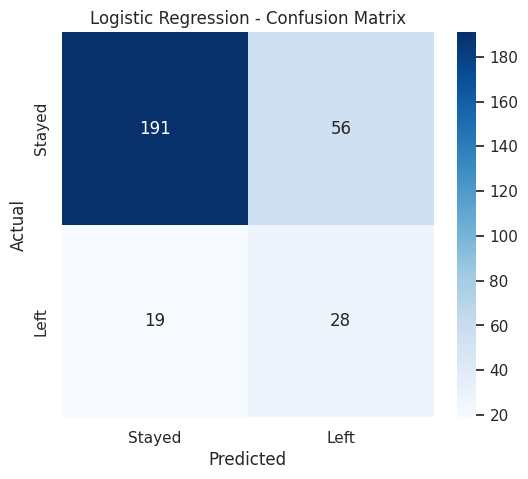

In [22]:
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

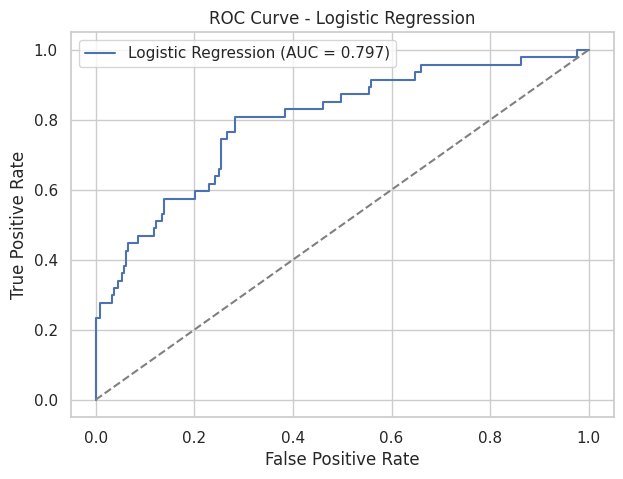

In [23]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_lr)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {lr_roc_auc:.3f})'
)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')

plt.legend()
plt.show()

In [24]:
decision_tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        criterion='gini',
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42
    ))
])

print("Decision Tree initialized successfully!")

Decision Tree initialized successfully!


In [25]:
decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [26]:
y_pred_dt = decision_tree_model.predict(X_test)

y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree predictions generated!")

Decision Tree predictions generated!


In [27]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, zero_division=0)
dt_recall = recall_score(y_test, y_pred_dt, zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, zero_division=0)
dt_roc_auc = roc_auc_score(y_test, y_prob_dt)

print("========== DECISION TREE RESULTS ==========")

print(f"Accuracy  : {dt_accuracy:.4f}")
print(f"Precision : {dt_precision:.4f}")
print(f"Recall    : {dt_recall:.4f}")
print(f"F1 Score  : {dt_f1:.4f}")
print(f"ROC-AUC   : {dt_roc_auc:.4f}")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=['Stayed', 'Left']
))

========== DECISION TREE RESULTS ==========
Accuracy  : 0.7483
Precision : 0.3247
Recall    : 0.5319
F1 Score  : 0.4032
ROC-AUC   : 0.6323

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.79      0.84       247
        Left       0.32      0.53      0.40        47

    accuracy                           0.75       294
   macro avg       0.61      0.66      0.62       294
weighted avg       0.81      0.75      0.77       294



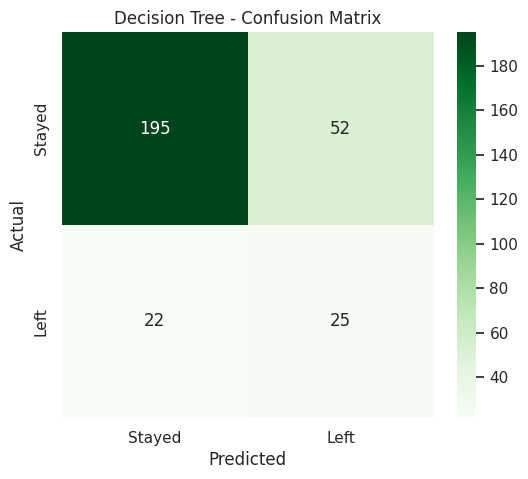

In [28]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

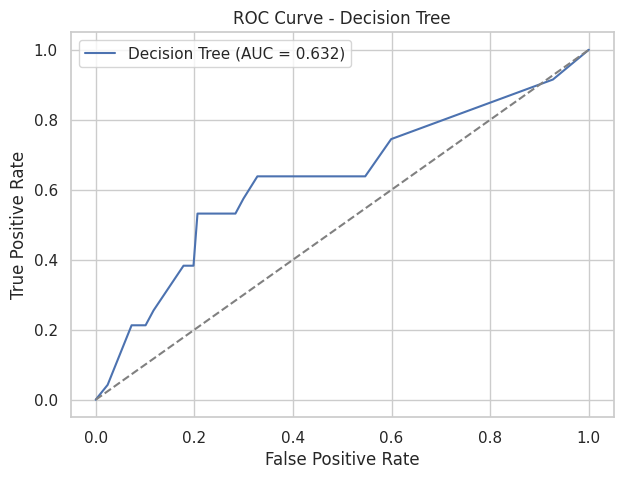

In [29]:
fpr_dt, tpr_dt, thresholds_dt = roc_curve(
    y_test, y_prob_dt
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f'Decision Tree (AUC = {dt_roc_auc:.3f})'
)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree')

plt.legend()
plt.show()

In [30]:
results = [
    {
        'Model': 'Logistic Regression',
        'Accuracy': lr_accuracy,
        'Precision': lr_precision,
        'Recall': lr_recall,
        'F1 Score': lr_f1,
        'ROC-AUC': lr_roc_auc
    },
    {
        'Model': 'Decision Tree',
        'Accuracy': dt_accuracy,
        'Precision': dt_precision,
        'Recall': dt_recall,
        'F1 Score': dt_f1,
        'ROC-AUC': dt_roc_auc
    }
]

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.7449     0.3333  0.5957    0.4275   0.7970
      Decision Tree    0.7483     0.3247  0.5319    0.4032   0.6323


In [31]:
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest initialized successfully!")

Random Forest initialized successfully!


In [32]:
random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [33]:
y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated!")

Random Forest predictions generated!


In [34]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("========== RANDOM FOREST RESULTS ==========")

print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1 Score  : {rf_f1:.4f}")
print(f"ROC-AUC   : {rf_roc_auc:.4f}")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=['Stayed', 'Left']
))

========== RANDOM FOREST RESULTS ==========
Accuracy  : 0.8333
Precision : 0.4444
Recall    : 0.1702
F1 Score  : 0.2462
ROC-AUC   : 0.7772

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.86      0.96      0.91       247
        Left       0.44      0.17      0.25        47

    accuracy                           0.83       294
   macro avg       0.65      0.56      0.58       294
weighted avg       0.79      0.83      0.80       294



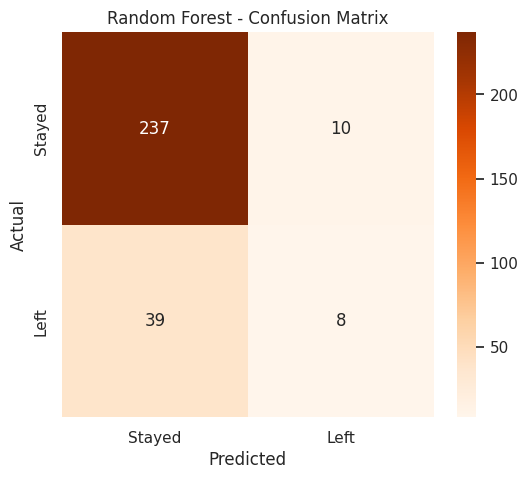

In [35]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

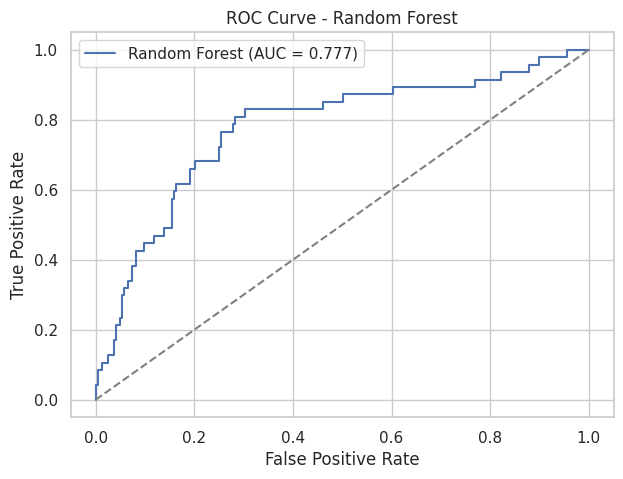

In [36]:
fpr_rf, tpr_rf, thresholds_rf = roc_curve(
    y_test, y_prob_rf
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f'Random Forest (AUC = {rf_roc_auc:.3f})'
)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')

plt.legend()
plt.show()

In [37]:
results.append({
    'Model': 'Random Forest',
    'Accuracy': rf_accuracy,
    'Precision': rf_precision,
    'Recall': rf_recall,
    'F1 Score': rf_f1,
    'ROC-AUC': rf_roc_auc
})

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.7449     0.3333  0.5957    0.4275   0.7970
      Decision Tree    0.7483     0.3247  0.5319    0.4032   0.6323
      Random Forest    0.8333     0.4444  0.1702    0.2462   0.7772


In [38]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Employees Stayed:", negative_count)
print("Employees Left:", positive_count)
print("Class Imbalance Ratio:", round(scale_pos_weight, 2))

Employees Stayed: 986
Employees Left: 190
Class Imbalance Ratio: 5.19


In [39]:
xgboost_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

print("XGBoost initialized successfully!")

XGBoost initialized successfully!


In [40]:
xgboost_model.fit(X_train, y_train)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [41]:
y_pred_xgb = xgboost_model.predict(X_test)

y_prob_xgb = xgboost_model.predict_proba(X_test)[:, 1]

print("XGBoost predictions generated successfully!")

XGBoost predictions generated successfully!


In [42]:
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

xgb_precision = precision_score(
    y_test, y_pred_xgb, zero_division=0
)

xgb_recall = recall_score(
    y_test, y_pred_xgb, zero_division=0
)

xgb_f1 = f1_score(
    y_test, y_pred_xgb, zero_division=0
)

xgb_roc_auc = roc_auc_score(y_test, y_prob_xgb)

print("========== XGBOOST RESULTS ==========")

print(f"Accuracy  : {xgb_accuracy:.4f}")
print(f"Precision : {xgb_precision:.4f}")
print(f"Recall    : {xgb_recall:.4f}")
print(f"F1 Score  : {xgb_f1:.4f}")
print(f"ROC-AUC   : {xgb_roc_auc:.4f}")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=['Stayed', 'Left']
))

========== XGBOOST RESULTS ==========
Accuracy  : 0.8231
Precision : 0.4468
Recall    : 0.4468
F1 Score  : 0.4468
ROC-AUC   : 0.7582

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.89      0.89      0.89       247
        Left       0.45      0.45      0.45        47

    accuracy                           0.82       294
   macro avg       0.67      0.67      0.67       294
weighted avg       0.82      0.82      0.82       294



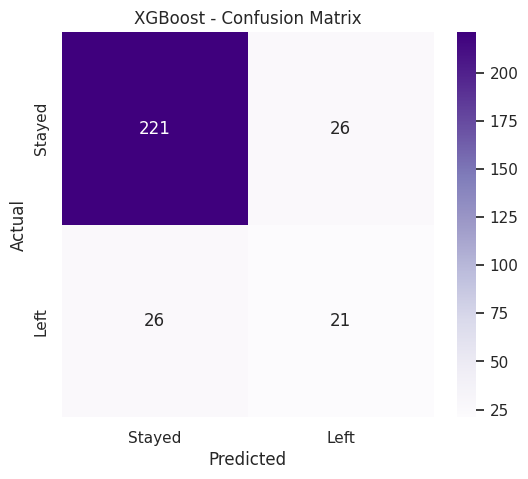

In [43]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('XGBoost - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

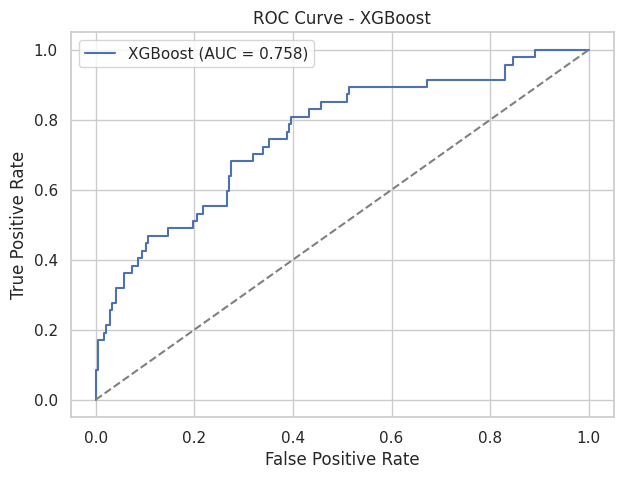

In [44]:
fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(
    y_test, y_prob_xgb
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f'XGBoost (AUC = {xgb_roc_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve - XGBoost')

plt.legend()
plt.show()

In [45]:
results.append({
    'Model': 'XGBoost',
    'Accuracy': xgb_accuracy,
    'Precision': xgb_precision,
    'Recall': xgb_recall,
    'F1 Score': xgb_f1,
    'ROC-AUC': xgb_roc_auc
})

results_df = pd.DataFrame(results)

print("========== FINAL MODEL COMPARISON ==========")

print(
    results_df.round(4).to_string(index=False)
)

========== FINAL MODEL COMPARISON ==========
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.7449     0.3333  0.5957    0.4275   0.7970
      Decision Tree    0.7483     0.3247  0.5319    0.4032   0.6323
      Random Forest    0.8333     0.4444  0.1702    0.2462   0.7772
            XGBoost    0.8231     0.4468  0.4468    0.4468   0.7582


**Model Evaluation and Comparison**

Four machine learning algorithms — Logistic Regression, Decision Tree, Random Forest, and XGBoost — were evaluated for employee attrition prediction.

The results show that XGBoost achieved the highest F1-score of 0.4468, indicating the best balance between precision and recall among the evaluated models. Logistic Regression achieved the highest ROC-AUC score of 0.7970 and recall of 0.5957.

Random Forest achieved the highest accuracy of 83.33%; however, its recall of 17.02% indicates that it failed to identify a significant proportion of employees who left the organization.

Therefore, XGBoost is selected as the best overall model based on F1-score, while Logistic Regression provides a useful alternative when identifying employees at risk of leaving is the primary objective.

TOP 15 IMPORTANT FEATURES


,Feature,Importance
7,JobLevel,0.055154
52,OverTime_No,0.051076
31,Department_Sales,0.037337
16,TotalWorkingYears,0.035486
15,StockOptionLevel,0.034417
19,YearsAtCompany,0.031292
23,TotalSatisfaction,0.028933
53,OverTime_Yes,0.026851
22,YearsWithCurrManager,0.026096
42,JobRole_Laboratory Technician,0.025224


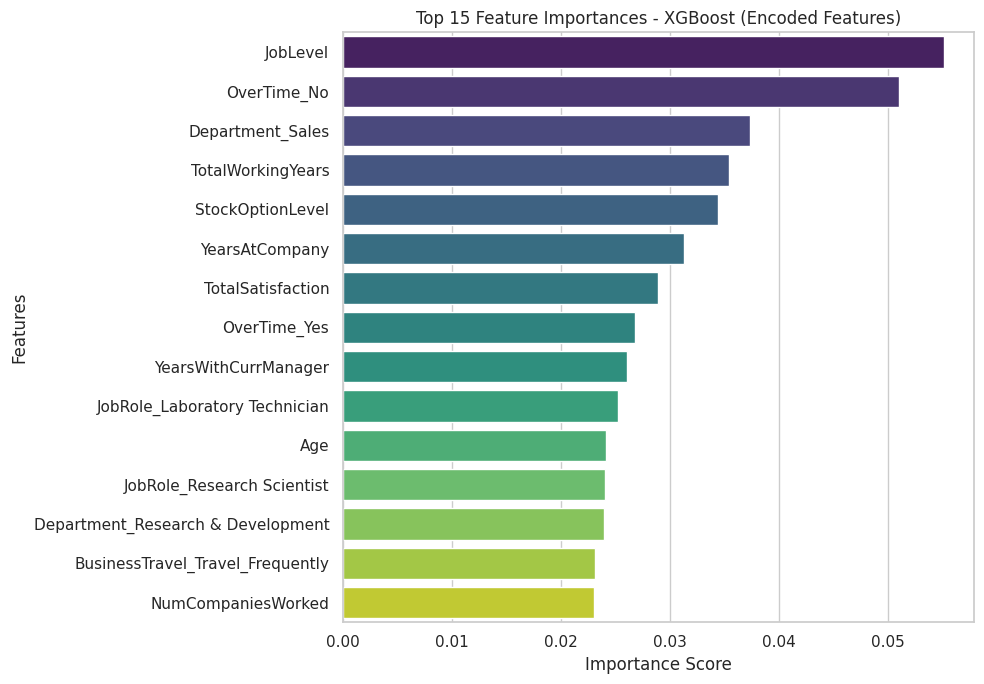

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Retrieve the fitted classifier from the pipeline
classifier = xgboost_model.named_steps['classifier']
importance = classifier.feature_importances_

# 2. Retrieve the transformed feature names from the preprocessor
preprocessor_step = xgboost_model.named_steps['preprocessor']

# Get numerical feature names
num_features = preprocessor_step.transformers_[0][2]

# Get one-hot encoded categorical feature names
cat_encoder = preprocessor_step.transformers_[1][1].named_steps['encoder']
cat_features_raw = preprocessor_step.transformers_[1][2]
cat_features_encoded = cat_encoder.get_feature_names_out(cat_features_raw).tolist()

# Combine all feature names
all_features = num_features + cat_features_encoded

# 3. Create DataFrame and sort
feature_importance = pd.DataFrame({
    'Feature': all_features,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

print("TOP 15 IMPORTANT FEATURES")
display(feature_importance.head(15))

# 4. Plot feature importance
plt.figure(figsize=(10, 7))

# Set hue to 'Feature' and legend to False to fix the FutureWarning
sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title('Top 15 Feature Importances - XGBoost (Encoded Features)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

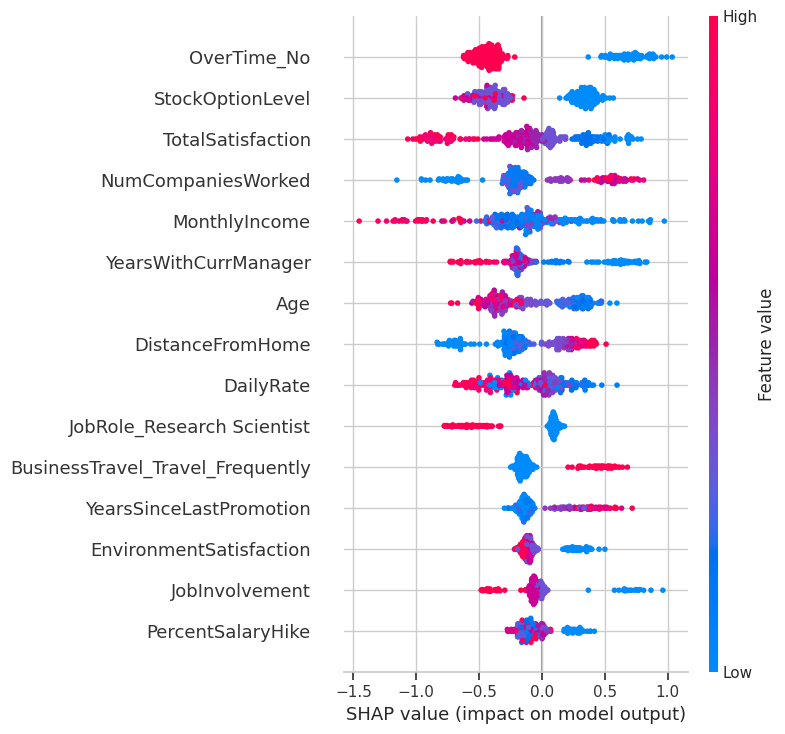

In [50]:
!pip install shap -q

import shap
import pandas as pd

# 1. Extract the preprocessor and the fitted XGBoost classifier from the pipeline
preprocessor_step = xgboost_model.named_steps['preprocessor']
xgb_classifier = xgboost_model.named_steps['classifier']

# 2. Transform the X_test dataset using the preprocessor pipeline
X_test_transformed = preprocessor_step.transform(X_test)

# 3. Retrieve feature names to make the plot readable
num_features = preprocessor_step.transformers_[0][2]
cat_encoder = preprocessor_step.transformers_[1][1].named_steps['encoder']
cat_features_raw = preprocessor_step.transformers_[1][2]
cat_features_encoded = cat_encoder.get_feature_names_out(cat_features_raw).tolist()
all_features = num_features + cat_features_encoded

# Convert transformed data into a DataFrame with original feature names
X_test_processed_df = pd.DataFrame(X_test_transformed, columns=all_features)

# 4. Initialize the SHAP TreeExplainer using the underlying model
explainer = shap.TreeExplainer(xgb_classifier)
shap_values = explainer.shap_values(X_test_processed_df)

# 5. Plot the SHAP summary
shap.summary_plot(
    shap_values,
    X_test_processed_df,
    max_display=15
)